# Reinforcement Learning: Q-Learning on CartPole

The MNIST and CNN notebooks cover **supervised learning** — learning from labeled examples. The genetic algorithms notebook covers **evolutionary optimization** — learning through selection and mutation. Reinforcement learning is a third paradigm.

In RL, an **agent** interacts with an **environment** by taking **actions** and receiving **rewards**. The agent's goal is to learn a **policy** — a strategy for choosing actions — that maximizes total reward over time. There are no labeled examples: the agent discovers what works by trying things.

```
┌─────────────────────────────────────────────┐
│                                             │
│   Agent ──── action ────→ Environment       │
│     ↑                          │            │
│     └────── reward, state ─────┘            │
│                                             │
└─────────────────────────────────────────────┘
```

Examples: playing video games, robot locomotion, trading, recommendation systems, AlphaGo.

## Dependencies

In [1]:
%pip install gymnasium matplotlib numpy --quiet


[notice] A new release of pip is available: 25.3 -> 26.1.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import gymnasium as gym
import matplotlib.pyplot as plt

## The CartPole environment

CartPole-v1 is the classic RL benchmark: a pole is balanced on a cart that moves left or right on a frictionless track. The agent must keep the pole upright.

- **State**: 4 continuous values — `[cart_pos, cart_vel, pole_angle, pole_ang_vel]`
- **Actions**: 0 (push left) or 1 (push right)
- **Reward**: +1 for every timestep the pole stays upright
- **Termination**: pole angle > 12°, cart out of bounds (±2.4), or 500 steps reached

A random agent averages ~12 steps. A well-trained agent reaches the 500-step cap consistently.

In [3]:
env = gym.make('CartPole-v1')
obs, info = env.reset()

print(f'Observation space: {env.observation_space}')
print(f'Action space:      {env.action_space}')
print(f'\nInitial state: {obs}')
print(f'  Cart position:      {obs[0]:.4f}  (bounds: ±4.8)')
print(f'  Cart velocity:      {obs[1]:.4f}')
print(f'  Pole angle (rad):   {obs[2]:.4f}  (bounds: ±0.418)')
print(f'  Pole angular vel:   {obs[3]:.4f}')

# Random agent baseline
random_rewards = []
for _ in range(200):
    obs, _ = env.reset()
    total = 0
    for _ in range(500):
        action = env.action_space.sample()
        obs, reward, terminated, truncated, _ = env.step(action)
        total += reward
        if terminated or truncated:
            break
    random_rewards.append(total)

print(f'\nRandom agent average reward: {np.mean(random_rewards):.1f} steps')
env.close()

Observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
Action space:      Discrete(2)

Initial state: [ 0.04234247  0.03312942  0.02722077 -0.01758503]
  Cart position:      0.0423  (bounds: ±4.8)
  Cart velocity:      0.0331
  Pole angle (rad):   0.0272  (bounds: ±0.418)
  Pole angular vel:   -0.0176

Random agent average reward: 22.5 steps


## Q-learning

Q-learning learns a **value function** Q(s, a) — the expected total future reward when taking action `a` in state `s`, then acting optimally afterwards.

The update rule (Bellman equation):
```
Q(s, a) ← Q(s, a) + α · [r + γ · max_a' Q(s', a')  −  Q(s, a)]
```

- **α** (learning rate): how much to update toward the new estimate. Typical: 0.1.
- **γ** (discount factor): how much to value future rewards vs. immediate ones. γ=0.99 values future rewards highly.
- **r + γ·max Q(s', a')**: the **TD target** — a better estimate of Q(s, a) using the observed reward and the next state.
- The term in brackets is the **TD error** — how wrong the current estimate was.

With enough updates, Q converges to the true value function.

## State discretization

Q-learning requires a **Q-table**: a lookup table indexed by (state, action). But CartPole's state is continuous — we can't have a table with infinitely many rows.

**Discretization** maps each continuous state variable into one of N discrete bins. With 10 bins per variable and 4 variables, the state space becomes 10⁴ = 10,000 discrete states — manageable as a table.

The tradeoff: coarser bins are faster to learn but lose precision; finer bins preserve more information but require more exploration to fill the table.

In [4]:
N_BINS = 10

# Bin edges for each state dimension
# Cart velocity and pole angular velocity are clipped to ±4 since they rarely exceed this
bins = [
    np.linspace(-4.8,   4.8,   N_BINS),   # cart position
    np.linspace(-4.0,   4.0,   N_BINS),   # cart velocity  (clipped)
    np.linspace(-0.418, 0.418, N_BINS),   # pole angle
    np.linspace(-4.0,   4.0,   N_BINS),   # pole angular velocity (clipped)
]

def discretize(obs):
    return tuple(np.digitize(obs[i], bins[i]) for i in range(4))

# Q-table: (N_BINS+1)^4 states × 2 actions, initialized to 0
Q = np.zeros((N_BINS + 1,) * 4 + (2,))
print(f'Q-table shape: {Q.shape}')
print(f'Total entries: {Q.size:,}')

Q-table shape: (11, 11, 11, 11, 2)
Total entries: 29,282


## Exploration vs. exploitation: ε-greedy

A core challenge in RL is the **exploration-exploitation tradeoff**:
- **Exploit**: choose the action with the highest Q value (greedy). Maximizes short-term reward but misses better strategies not yet discovered.
- **Explore**: choose a random action. Discovers new states but may perform worse in the short term.

**ε-greedy** balances both: with probability ε take a random action (explore), otherwise take the greedy action (exploit). ε starts at 1.0 (pure exploration) and decays each episode toward a minimum (mostly exploitation once the Q-table is well-populated).

## Training

In [5]:
ALPHA      = 0.1     # learning rate
GAMMA      = 0.99    # discount factor
EPSILON    = 1.0     # initial exploration rate
EPS_DECAY  = 0.995   # decay factor per episode
EPS_MIN    = 0.01    # minimum exploration rate
N_EPISODES = 5000

rewards_per_episode = []
env = gym.make('CartPole-v1')

for ep in range(N_EPISODES):
    obs, _ = env.reset()
    state  = discretize(obs)
    total_reward = 0

    for _ in range(500):
        # Epsilon-greedy action selection
        if np.random.rand() < EPSILON:
            action = env.action_space.sample()  # explore
        else:
            action = np.argmax(Q[state])         # exploit

        next_obs, reward, terminated, truncated, _ = env.step(action)
        next_state = discretize(next_obs)
        done = terminated or truncated

        # Q-table update (Bellman equation)
        td_target = reward + GAMMA * np.max(Q[next_state]) * (not done)
        Q[state][action] += ALPHA * (td_target - Q[state][action])

        state = next_state
        total_reward += reward

        if done:
            break

    rewards_per_episode.append(total_reward)
    EPSILON = max(EPS_MIN, EPSILON * EPS_DECAY)

    if (ep + 1) % 500 == 0:
        recent_avg = np.mean(rewards_per_episode[-100:])
        print(f'Episode {ep+1:5d} | avg reward (last 100): {recent_avg:6.1f} | epsilon: {EPSILON:.3f}')

env.close()
print(f'\nTraining complete. Final epsilon: {EPSILON:.4f}')

Episode   500 | avg reward (last 100):   91.3 | epsilon: 0.082
Episode  1000 | avg reward (last 100):  115.3 | epsilon: 0.010
Episode  1500 | avg reward (last 100):  119.1 | epsilon: 0.010
Episode  2000 | avg reward (last 100):  127.7 | epsilon: 0.010
Episode  2500 | avg reward (last 100):  137.8 | epsilon: 0.010
Episode  3000 | avg reward (last 100):  150.9 | epsilon: 0.010
Episode  3500 | avg reward (last 100):  152.9 | epsilon: 0.010
Episode  4000 | avg reward (last 100):  163.2 | epsilon: 0.010
Episode  4500 | avg reward (last 100):  157.4 | epsilon: 0.010
Episode  5000 | avg reward (last 100):  158.8 | epsilon: 0.010

Training complete. Final epsilon: 0.0100


## Results

The smoothed reward curve shows the three phases typical of Q-learning:
1. **Exploration phase** (high ε): mostly random actions, low reward.
2. **Learning phase** (ε decaying): the Q-table fills in, reward rises quickly.
3. **Exploitation phase** (low ε): the policy stabilizes; performance plateaus.

The gap between the raw reward and the smoothed average shows episode-to-episode variance — some episodes the agent gets unlucky with the initial state.

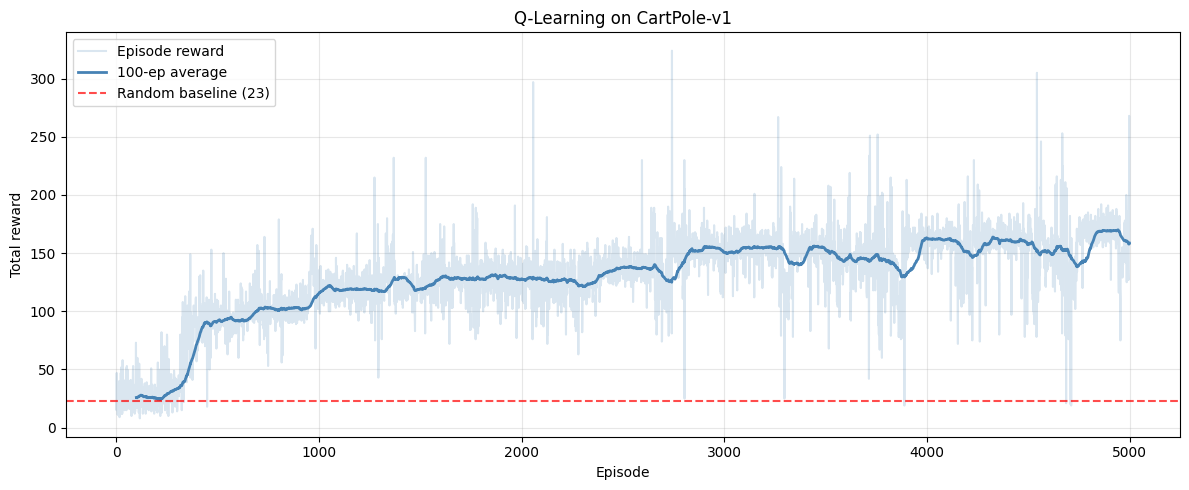

Random agent:         22.5 avg reward
Trained agent (last 100 eps): 158.8 avg reward


In [6]:
# Smooth with a rolling average
window = 100
smoothed = np.convolve(rewards_per_episode, np.ones(window) / window, mode='valid')

plt.figure(figsize=(12, 5))
plt.plot(rewards_per_episode, alpha=0.2, color='steelblue', label='Episode reward')
plt.plot(range(window - 1, N_EPISODES), smoothed, color='steelblue', linewidth=2, label=f'{window}-ep average')
plt.axhline(y=np.mean(random_rewards), color='red', linestyle='--', alpha=0.7, label=f'Random baseline ({np.mean(random_rewards):.0f})')
plt.xlabel('Episode')
plt.ylabel('Total reward')
plt.title('Q-Learning on CartPole-v1')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f'Random agent:         {np.mean(random_rewards):.1f} avg reward')
print(f'Trained agent (last 100 eps): {np.mean(rewards_per_episode[-100:]):.1f} avg reward')

## Evaluating the trained agent

Run 100 deterministic evaluation episodes (ε=0, always greedy) to measure the final policy quality.

Evaluation over 100 episodes:
  Mean reward:   169.7
  Median reward: 169.0
  Max reward:    184  (500 = perfect episode)
  Episodes with reward = 500: 0/100


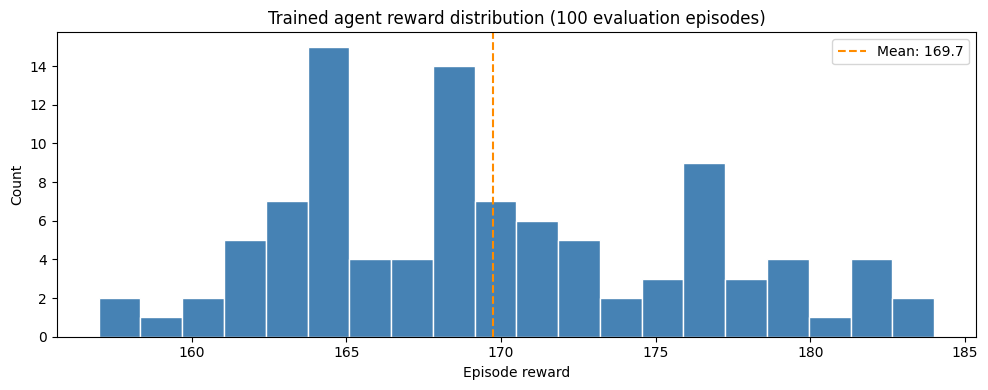

In [7]:
eval_rewards = []
env = gym.make('CartPole-v1')

for _ in range(100):
    obs, _ = env.reset()
    state  = discretize(obs)
    total  = 0
    for _ in range(500):
        action = np.argmax(Q[state])  # always greedy (no exploration)
        obs, reward, terminated, truncated, _ = env.step(action)
        state = discretize(obs)
        total += reward
        if terminated or truncated:
            break
    eval_rewards.append(total)

env.close()

print(f'Evaluation over 100 episodes:')
print(f'  Mean reward:   {np.mean(eval_rewards):.1f}')
print(f'  Median reward: {np.median(eval_rewards):.1f}')
print(f'  Max reward:    {np.max(eval_rewards):.0f}  (500 = perfect episode)')
print(f'  Episodes with reward = 500: {sum(r == 500 for r in eval_rewards)}/100')

plt.figure(figsize=(10, 4))
plt.hist(eval_rewards, bins=20, color='steelblue', edgecolor='white')
plt.xlabel('Episode reward')
plt.ylabel('Count')
plt.title('Trained agent reward distribution (100 evaluation episodes)')
plt.axvline(x=np.mean(eval_rewards), color='darkorange', linestyle='--', label=f'Mean: {np.mean(eval_rewards):.1f}')
plt.legend()
plt.tight_layout()
plt.show()

## Limitations and next steps

Tabular Q-learning works well on CartPole but breaks down on harder problems because:

- **Scalability**: with 4 continuous dimensions and 10 bins each, we have 10,000 states. A more complex problem (e.g., Atari with pixel inputs) would have billions of states — impossible to enumerate.
- **Generalization**: the Q-table treats each state independently. A state never visited during training has no Q-values — the agent has no idea what to do.

**Deep Q-Networks (DQN)** replace the table with a neural network that approximates Q(s, a) for any state, even ones never seen before. This was the breakthrough that enabled RL on Atari games (DeepMind, 2015). More recent algorithms — PPO, SAC, TD3 — extend this further with better stability and sample efficiency.